In [1]:
import pandas as pd
import matplotlib.pyplot as plt
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
data = {
    "Month": [
        "January", "February", "March",
        "April", "May", "June"
    ],
    "Laptop": [45000, 48000, 52000, 50000, 56000, 60000],
    "Mobile": [30000, 32000, 35000, 34000, 38000, 42000],
    "Headphones": [12000, 14000, 13500, 16000, 18000, 20000],
    "Keyboard": [8000, 8500, 9000, 9500, 10000, 11000],
    "Mouse": [5000, 5500, 6000, 5800, 6500, 7000]
}

df = pd.DataFrame(data)

df

,Month,Laptop,Mobile,Headphones,Keyboard,Mouse
0,January,45000,30000,12000,8000,5000
1,February,48000,32000,14000,8500,5500
2,March,52000,35000,13500,9000,6000
3,April,50000,34000,16000,9500,5800
4,May,56000,38000,18000,10000,6500
5,June,60000,42000,20000,11000,7000


In [3]:
df.to_csv("sales_data.csv", index=False)

print("Dataset saved successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset saved successfully!
Dataset shape: (6, 6)

First five rows:


,Month,Laptop,Mobile,Headphones,Keyboard,Mouse
0,January,45000,30000,12000,8000,5000
1,February,48000,32000,14000,8500,5500
2,March,52000,35000,13500,9000,6000
3,April,50000,34000,16000,9500,5800
4,May,56000,38000,18000,10000,6500



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Month       6 non-null      str  
 1   Laptop      6 non-null      int64
 2   Mobile      6 non-null      int64
 3   Headphones  6 non-null      int64
 4   Keyboard    6 non-null      int64
 5   Mouse       6 non-null      int64
dtypes: int64(5), str(1)
memory usage: 420.0 bytes


In [4]:
product_columns = [
    "Laptop", "Mobile", "Headphones", "Keyboard", "Mouse"
]

product_sales = df[product_columns].sum()

print("Total sales by product:")
display(product_sales.sort_values(ascending=False))

print("\nHighest-selling product:", product_sales.idxmax())
print("Lowest-selling product:", product_sales.idxmin())

Total sales by product:


Laptop        311000
Mobile        211000
Headphones     93500
Keyboard       56000
Mouse          35800
dtype: int64


Highest-selling product: Laptop
Lowest-selling product: Mouse


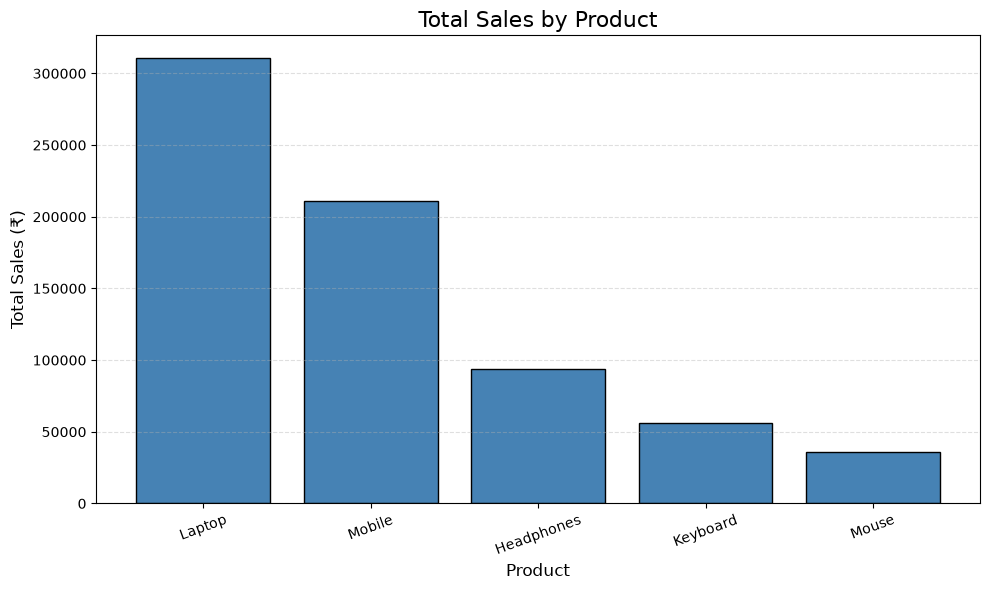

In [5]:
plt.figure(figsize=(10, 6))

plt.bar(
    product_sales.index,
    product_sales.values,
    color="steelblue",
    edgecolor="black"
)

plt.title("Total Sales by Product", fontsize=16)
plt.xlabel("Product", fontsize=12)
plt.ylabel("Total Sales (₹)", fontsize=12)
plt.xticks(rotation=20)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [6]:
df["Total_Sales"] = df[product_columns].sum(axis=1)

print("Monthly sales:")
display(df[["Month", "Total_Sales"]])

print("\nOverall sales:", df["Total_Sales"].sum())
print("Average monthly sales:", round(df["Total_Sales"].mean(), 2))

Monthly sales:


,Month,Total_Sales
0,January,100000
1,February,108000
2,March,115500
3,April,115300
4,May,128500
5,June,140000



Overall sales: 707300
Average monthly sales: 117883.33


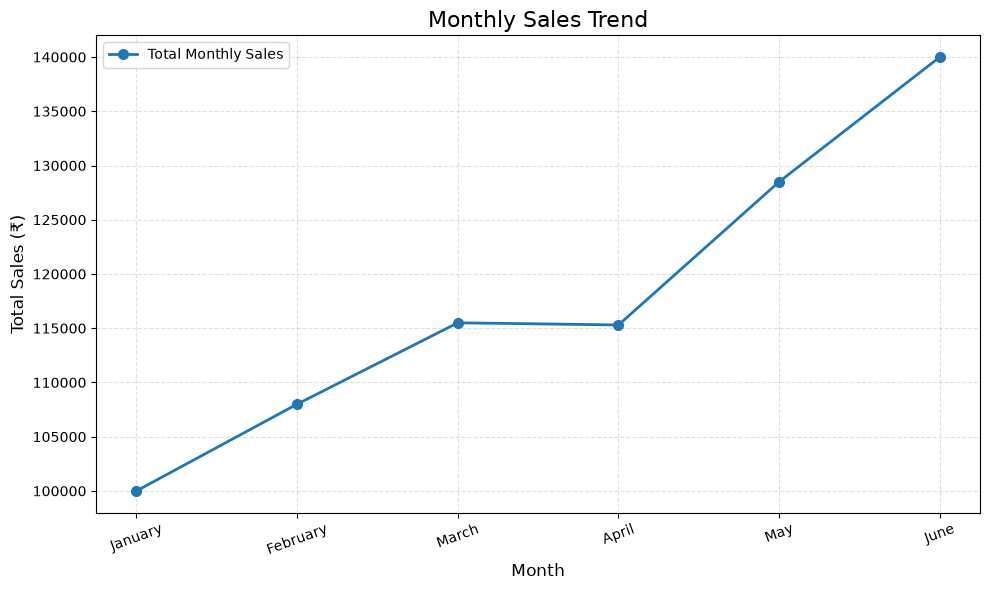

In [7]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["Month"],
    df["Total_Sales"],
    marker="o",
    linewidth=2,
    markersize=7,
    label="Total Monthly Sales"
)

plt.title("Monthly Sales Trend", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Sales (₹)", fontsize=12)
plt.xticks(rotation=20)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()

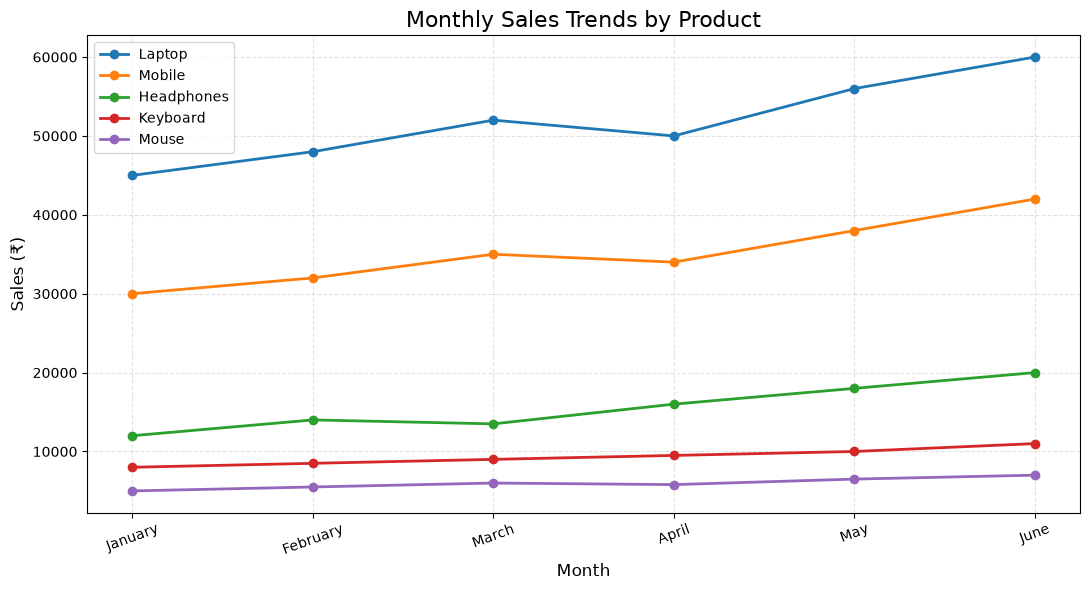

In [8]:
plt.figure(figsize=(11, 6))

for product in product_columns:
    plt.plot(
        df["Month"],
        df[product],
        marker="o",
        linewidth=2,
        label=product
    )

plt.title("Monthly Sales Trends by Product", fontsize=16)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Sales (₹)", fontsize=12)
plt.xticks(rotation=20)
plt.grid(True, linestyle="--", alpha=0.35)
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
best_month = df.loc[df["Total_Sales"].idxmax(), "Month"]
worst_month = df.loc[df["Total_Sales"].idxmin(), "Month"]

first_month_sales = df["Total_Sales"].iloc[0]
last_month_sales = df["Total_Sales"].iloc[-1]

growth = (
    (last_month_sales - first_month_sales)
    / first_month_sales
) * 100

print("SALES DATA ANALYSIS")
print("-" * 35)
print(f"Highest sales month: {best_month}")
print(f"Lowest sales month: {worst_month}")
print(f"January sales: ₹{first_month_sales:,.0f}")
print(f"June sales: ₹{last_month_sales:,.0f}")
print(f"January-to-June growth: {growth:.2f}%")

print("\nKey observations:")
print("1. Laptop contributes the highest total sales.")
print("2. Mouse contributes the lowest total sales.")
print("3. Overall monthly sales increase from January to June.")
print("4. June records the highest monthly sales in this dataset.")

SALES DATA ANALYSIS
-----------------------------------
Highest sales month: June
Lowest sales month: January
January sales: ₹100,000
June sales: ₹140,000
January-to-June growth: 40.00%

Key observations:
1. Laptop contributes the highest total sales.
2. Mouse contributes the lowest total sales.
3. Overall monthly sales increase from January to June.
4. June records the highest monthly sales in this dataset.


In [11]:
summary = pd.DataFrame({
    "Product": product_sales.index,
    "Total_Sales": product_sales.values
}).sort_values("Total_Sales", ascending=False)

summary.to_csv("product_sales_summary.csv", index=False)

print("Final product sales summary saved successfully!")
display(summary)

Final product sales summary saved successfully!


,Product,Total_Sales
0,Laptop,311000
1,Mobile,211000
2,Headphones,93500
3,Keyboard,56000
4,Mouse,35800
